
--- DBSCAN Clustering Results ---
Epsilon (eps): 1.35, Min Samples: 10
Clusters Formed: 1
Detected Noise / Outlier Points: 175 (4.76%)

--- Performance Comparison: DBSCAN vs K-Means on Noisy Telemetry ---
Algorithm  Clusters Found Noise Handled Separately?  Silhouette Score
   DBSCAN               1          Yes (Labeled -1)            0.8302
  K-Means               3     No (Absorbs Outliers)            0.3831

Experiment 12 Completed Successfully


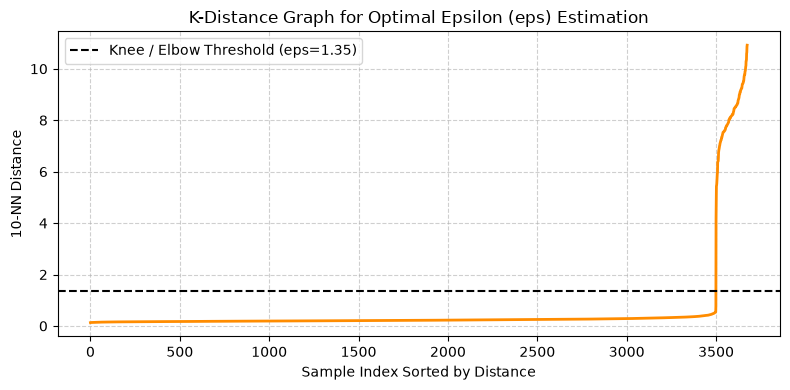

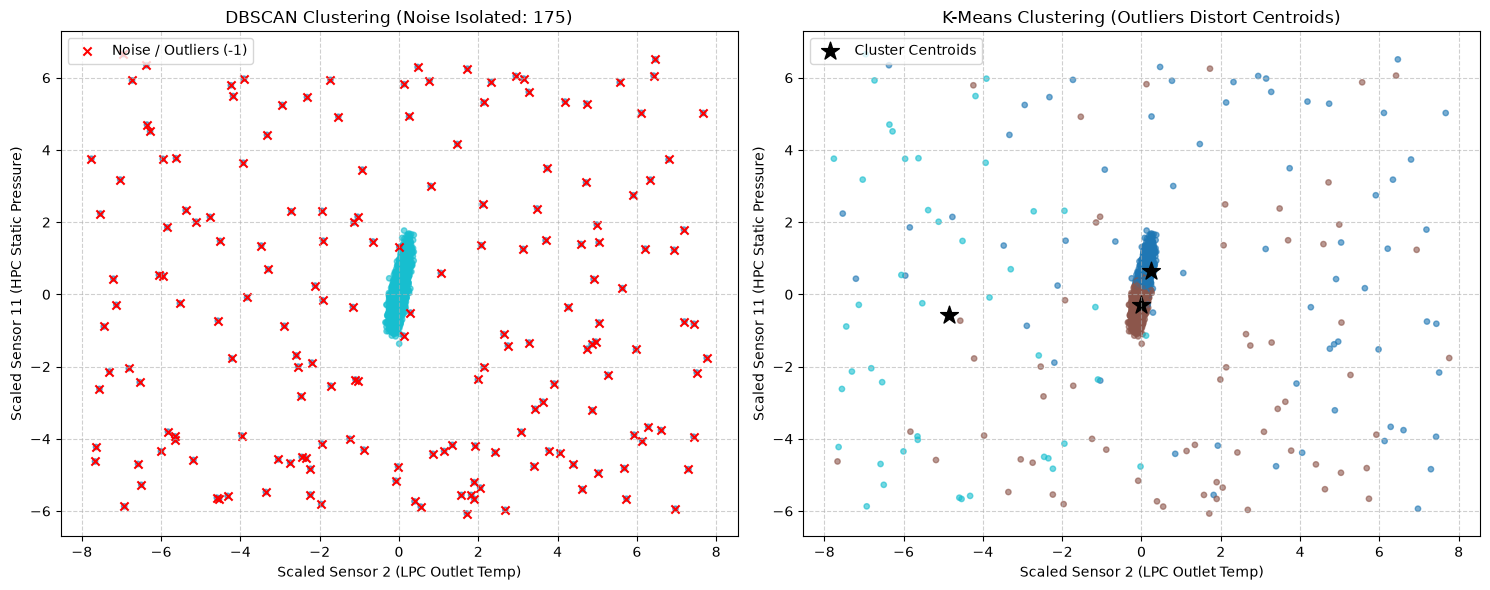

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import silhouette_score


# Load C-MAPSS telemetry dataset
cols = ["engine_id", "cycle", "setting_1", "setting_2", "setting_3"] + [f"sensor_{i}" for i in range(1, 22)]
df = pd.read_csv("../dataset/CMAPSSData/train_FD001.txt", sep=r"\s+", header=None, names=cols)

# Select key sensor degradation features
sensor_cols = ["sensor_2", "sensor_3", "sensor_4", "sensor_7", "sensor_11", "sensor_12"]
np.random.seed(42)
sample_subset = df[sensor_cols].sample(n=3500, random_state=42).copy()

# Inject 5% realistic sensor anomalies / burst noise to benchmark robustness
n_noise = int(len(sample_subset) * 0.05)
noise_data = np.random.uniform(
    low=sample_subset.min().values * 0.95,
    high=sample_subset.max().values * 1.05,
    size=(n_noise, sample_subset.shape[1])
)
noise_df = pd.DataFrame(noise_data, columns=sensor_cols)

X_noisy = pd.concat([sample_subset, noise_df], axis=0).reset_index(drop=True)

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_noisy)

# 1. K-Distance Graph to determine optimal epsilon (eps)
k_neighbors = 10
neighbors = NearestNeighbors(n_neighbors=k_neighbors)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

# Sort distances to 10th nearest neighbor
distances_sorted = np.sort(distances[:, k_neighbors - 1])

plt.figure(figsize=(8, 4))
plt.plot(distances_sorted, color='darkorange', lw=2)
plt.axhline(y=1.35, color='black', linestyle='--', label='Knee / Elbow Threshold (eps=1.35)')
plt.xlabel("Sample Index Sorted by Distance")
plt.ylabel(f"{k_neighbors}-NN Distance")
plt.title("K-Distance Graph for Optimal Epsilon (eps) Estimation")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

# 2. Fit DBSCAN with optimal parameters
optimal_eps = 1.35
min_samples = 10

dbscan = DBSCAN(eps=optimal_eps, min_samples=min_samples)
dbscan_labels = dbscan.fit_predict(X_scaled)

n_db_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_db_noise = list(dbscan_labels).count(-1)

print(f"\n--- DBSCAN Clustering Results ---")
print(f"Epsilon (eps): {optimal_eps}, Min Samples: {min_samples}")
print(f"Clusters Formed: {n_db_clusters}")
print(f"Detected Noise / Outlier Points: {n_db_noise} ({n_db_noise / len(X_scaled) * 100:.2f}%)")

# 3. Fit K-Means on the exact same noisy dataset for comparative analysis
n_km_clusters = 3
kmeans = KMeans(n_clusters=n_km_clusters, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

# Calculate silhouette scores
db_sil = silhouette_score(X_scaled, dbscan_labels)
km_sil = silhouette_score(X_scaled, kmeans_labels)

comparison_summary = pd.DataFrame({
    "Algorithm": ["DBSCAN", "K-Means"],
    "Clusters Found": [n_db_clusters, n_km_clusters],
    "Noise Handled Separately?": ["Yes (Labeled -1)", "No (Absorbs Outliers)"],
    "Silhouette Score": [round(db_sil, 4), round(km_sil, 4)]
})
print("\n--- Performance Comparison: DBSCAN vs K-Means on Noisy Telemetry ---")
print(comparison_summary.to_string(index=False))

# 4. Side-by-side Visual Comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# DBSCAN Plot
scatter_db = axes[0].scatter(
    X_scaled[:, 0], X_scaled[:, 4],
    c=dbscan_labels, cmap="tab10", s=15, alpha=0.6
)
axes[0].scatter(
    X_scaled[dbscan_labels == -1, 0], X_scaled[dbscan_labels == -1, 4],
    color='red', marker='x', s=35, label='Noise / Outliers (-1)'
)
axes[0].set_xlabel("Scaled Sensor 2 (LPC Outlet Temp)")
axes[0].set_ylabel("Scaled Sensor 11 (HPC Static Pressure)")
axes[0].set_title(f"DBSCAN Clustering (Noise Isolated: {n_db_noise})")
axes[0].legend(loc="upper left")
axes[0].grid(True, linestyle="--", alpha=0.6)

# K-Means Plot
scatter_km = axes[1].scatter(
    X_scaled[:, 0], X_scaled[:, 4],
    c=kmeans_labels, cmap="tab10", s=15, alpha=0.6
)
axes[1].scatter(
    kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 4],
    color='black', marker='*', s=180, label='Cluster Centroids'
)
axes[1].set_xlabel("Scaled Sensor 2 (LPC Outlet Temp)")
axes[1].set_ylabel("Scaled Sensor 11 (HPC Static Pressure)")
axes[1].set_title(f"K-Means Clustering (Outliers Distort Centroids)")
axes[1].legend(loc="upper left")
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.show()

print("Experiment 12 Completed Successfully")